<a href="https://colab.research.google.com/github/SamShinwari/tensorflow-from-scratch/blob/main/TensorFlow_%E2%80%94_Day_1%2C_Part_7_Linear_Regression_with_TensorFlow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Our Problem: Can a Model Learn?

Suppose we have data showing how many hours students study and the marks they receive.

| Study Hours ($x$) | Marks ($y$) |
|:---:|:---:|
| 1 | 3 |
| 2 | 5 |
| 3 | 7 |
| 4 | 9 |
| 5 | 11 |

### Our Goal

Can a machine learning model learn the relationship between study hours and marks?

The pattern in our data is:

$$
y = 2x + 1
$$

**Important:** We will not give this equation to the model!

Instead, we will initialize the model's parameters with some initial values and let training discover suitable values using the data.

By the end of this exercise, our model should learn that:

- **Weight ($w$):** Approximately 2
- **Bias ($b$):** Approximately 1

Our model uses the equation:

$$
\hat{y} = wx + b
$$

Here, $\hat{y}$ represents the marks predicted by the model.

Let's teach our model to discover the relationship on its own!

#Prepare the training data

In [7]:
import tensorflow as tf

# Input features
X = tf.constant([1., 2., 3., 4., 5.])

# Correct target values for y = 3x + 2
y_true = tf.constant([5., 8., 11., 14., 17.])

print("Inputs:", X.numpy())
print("Targets:", y_true.numpy())
print("Number of examples:", X.shape[0])

Inputs: [1. 2. 3. 4. 5.]
Targets: [ 5.  8. 11. 14. 17.]
Number of examples: 5


#Create the model

In [8]:
w = tf.Variable(0.0)
b = tf.Variable(0.0)

def predict(X):
    return w * X + b

print("Initial predictions:", predict(X).numpy())

Initial predictions: [0. 0. 0. 0. 0.]


#Calculate the loss

In [3]:
def calculate_loss(y_true, y_pred):
    return tf.reduce_mean(tf.square(y_true - y_pred))

initial_loss = calculate_loss(y_true, predict(X))

print("Initial loss:", initial_loss.numpy())

Initial loss: 57.0


#Train the model using gradient descent
Now we'll combine everything from the previous lessons:
- tf.GradientTape() calculates gradients.
- tf.reduce_mean() calculates the average loss.
- assign_sub() updates the model parameters.
- A loop repeats the learning process.

In [10]:
learning_rate = 0.01
epochs = 1000

# Reset variables for training
w.assign(0.0)
b.assign(0.0)

for epoch in range(epochs):
    with tf.GradientTape() as tape:
        y_pred = predict(X)
        loss = calculate_loss(y_true, y_pred)

    dw, db = tape.gradient(loss, [w, b])
    w.assign_sub(learning_rate * dw)
    b.assign_sub(learning_rate * db)

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Loss = {loss.numpy():.6f}, "
            f"w = {w.numpy():.4f}, "
            f"b = {b.numpy():.4f}"
        )

Epoch 100: Loss = 0.109736, w = 3.2143, b = 1.2262
Epoch 200: Loss = 0.055743, w = 3.1528, b = 1.4485
Epoch 300: Loss = 0.028315, w = 3.1089, b = 1.6069
Epoch 400: Loss = 0.014383, w = 3.0776, b = 1.7198
Epoch 500: Loss = 0.007306, w = 3.0553, b = 1.8003
Epoch 600: Loss = 0.003711, w = 3.0394, b = 1.8577
Epoch 700: Loss = 0.001885, w = 3.0281, b = 1.8986
Epoch 800: Loss = 0.000958, w = 3.0200, b = 1.9277
Epoch 900: Loss = 0.000486, w = 3.0143, b = 1.9485
Epoch 1000: Loss = 0.000247, w = 3.0102, b = 1.9633


#Test the trained model

In [11]:
new_student = tf.constant(6.0)
predicted_marks = predict(new_student)

print("Learned weight:", w.numpy())
print("Learned bias:", b.numpy())
print("Predicted marks for x = 6:", predicted_marks.numpy())
print("Expected marks for x = 6:", 20.0)

Learned weight: 3.0101707
Learned bias: 1.9632801
Predicted marks for x = 6: 20.024303
Expected marks for x = 6: 20.0


#Visualize the model's predictions

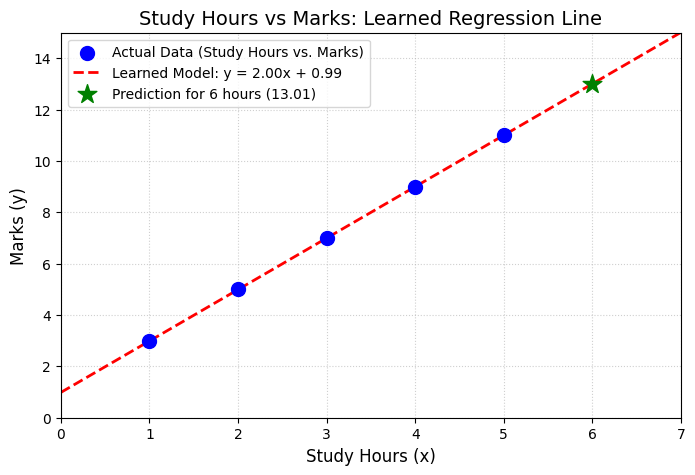

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Convert tensors to numpy arrays for plotting
X_np = X.numpy()
y_true_np = y_true.numpy()

# Generate points for the regression line using our learned weight and bias
x_range = np.linspace(0, 7, 100)
y_pred_line = w.numpy() * x_range + b.numpy()

# Create the plot
plt.figure(figsize=(8, 5))
plt.scatter(X_np, y_true_np, color='blue', label='Actual Data (Study Hours vs. Marks)', s=100, zorder=5)
plt.plot(x_range, y_pred_line, color='red', linestyle='--', linewidth=2, label=f'Learned Model: y = {w.numpy():.2f}x + {b.numpy():.2f}')

# Include the new student prediction as a reference
plt.scatter([6.0], [predicted_marks.numpy()], color='green', marker='*', s=200, label=f'Prediction for 6 hours ({predicted_marks.numpy():.2f})', zorder=6)

# Formatting
plt.title("Study Hours vs Marks: Learned Regression Line", fontsize=14)
plt.xlabel("Study Hours (x)", fontsize=12)
plt.ylabel("Marks (y)", fontsize=12)
plt.xlim(0, 7)
plt.ylim(0, 15)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()